# Optimasi Random Forest Regression — Prediksi Penjualan

Pipeline ilmiah lengkap: data understanding → cleaning → EDA → feature engineering → anti-leakage → split waktu → baseline → TimeSeries CV → hyperparameter tuning → eksperimen bertahap → evaluasi final → feature importance → residual analysis → prediksi periode berikutnya → penyimpanan model.

**Model utama:** Random Forest Regression (target growth + rekonstruksi level).
**Tujuan:** akurasi (R²) > 90% dengan MAE/MSE/RMSE/MAPE serendah mungkin.

In [1]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             top_k_accuracy_score)

## 1. Import Library
Sudah dilakukan.

## 2. Load Dataset

In [2]:
# ===== Load dataset =====
TRX_PATH = 'dataset/transaksi (2).csv'
CUST_PATH = 'dataset/customer (2).csv'
df = pd.read_csv(TRX_PATH, parse_dates=['tanggal'])
cust_df = pd.read_csv(CUST_PATH)
print('Dataset dimuat.')
print('Transaksi shape:', df.shape)
print('Customer shape :', cust_df.shape)
print('Rentang data    :', df['tanggal'].min().date(), 's/d', df['tanggal'].max().date())
print('Unit nilai      : ribuan rupiah')

Dataset dimuat.
Transaksi shape: (1200, 12)
Customer shape : (40, 6)
Rentang data    : 2022-01-02 s/d 2025-12-27
Unit nilai      : ribuan rupiah


## 3. Data Understanding

In [3]:
# ===== 3a. Informasi umum =====
print('--- Nama variabel ---')
print(list(df.columns))
print()
print('--- Tipe data ---')
print(df.dtypes.to_string())
print()
print(f'Baris : {len(df)}, Kolom : {df.shape[1]}')


--- Nama variabel ---
['id', 'tanggal', 'kode_cust', 'keterangan', 'qty', 'satuan', 'harga', 'total', 'bulan', 'tahun', 'tipe_customer', 'tipe_produk']

--- Tipe data ---
id                          str
tanggal          datetime64[us]
kode_cust                   str
keterangan                  str
qty                       int64
satuan                      str
harga                   float64
total                   float64
bulan                       str
tahun                     int64
tipe_customer               str
tipe_produk                 str

Baris : 1200, Kolom : 12


In [4]:
# ===== 3b. Statistik deskriptif =====
print(df[['qty', 'harga', 'total', 'tahun']].describe().to_string())
print()
print('--- Missing & duplikasi ---')
print(f'Missing : {int(df.isna().sum().sum())}')
print(f'harga=0 : {int((df["harga"] == 0).sum())} | total=0 : {int((df["total"] == 0).sum())}')

               qty        harga        total        tahun
count  1200.000000  1200.000000  1200.000000  1200.000000
mean      4.752500   271.615000   687.505000  2023.765833
std       2.655269   504.993674   668.535798     1.094073
min       1.000000     5.000000    19.000000  2022.000000
25%       3.000000    30.750000   140.000000  2023.000000
50%       5.000000   131.000000   440.500000  2024.000000
75%       7.000000   217.250000   990.000000  2025.000000
max      13.000000  3314.000000  3314.000000  2025.000000

--- Missing & duplikasi ---
Missing : 0
harga=0 : 0 | total=0 : 0


## 4. Data Cleaning

Verifikasi konsistensi data: `qty × harga = total`, relasi customer, konsistensi tanggal/bulan/tahun. Tidak ada penghapusan data.

In [5]:
# ===== 4. Verifikasi konsistensi =====
qty_num = pd.to_numeric(df['qty'].astype(str).str.extract(r'([\d.]+)')[0], errors='coerce')
selisih = (qty_num * df['harga'] - df['total']).abs()
print(f'qty x harga vs total (selisih > 1): {int((selisih > 1).sum())} dari {len(df)}')
print(f'kode_cust tanpa id customer       : {len(set(df["kode_cust"]) - set(cust_df["id"]))}')
bulan_id = ['Januari', 'Februari', 'Maret', 'April', 'Mei', 'Juni', 'Juli',
            'Agustus', 'September', 'Oktober', 'November', 'Desember']
dt = pd.to_datetime(df['tanggal'], errors='coerce')
print(f'bulan != tanggal : {int((df["bulan"] != dt.dt.month.map(lambda m: bulan_id[m-1])).sum())}')
print(f'tahun != tanggal : {int((df["tahun"] != dt.dt.year).sum())}')

qty x harga vs total (selisih > 1): 0 dari 1200
kode_cust tanpa id customer       : 0
bulan != tanggal : 0
tahun != tanggal : 0


## 5. Exploratory Data Analysis (EDA)

In [6]:
# ===== 5a. Agregasi bulanan =====
df['periode'] = df['tanggal'].dt.to_period('M').astype(str)
bulanan = (df.groupby('periode')
           .agg(total_revenue_bulan=('total', 'sum'),
                n_transaksi=('id', 'count'), qty_total=('qty', 'sum'),
                n_produk_unik=('tipe_produk', 'nunique'),
                n_customer_unik=('kode_cust', 'nunique'))
           .reset_index())
bulanan['tahun'] = bulanan['periode'].str[:4].astype(int)
bulanan['bulan_num'] = bulanan['periode'].str[5:7].astype(int)
bulanan['avg_transaksi'] = bulanan['total_revenue_bulan'] / bulanan['n_transaksi']

print(bulanan['total_revenue_bulan'].describe().to_string())
print()
print('Periode:', bulanan['periode'].min(), 's/d', bulanan['periode'].max(), f'({len(bulanan)} bulan)')

count       48.000000
mean     17187.625000
std       3520.648052
min      11313.000000
25%      14387.000000
50%      16875.000000
75%      19326.500000
max      25166.000000

Periode: 2022-01 s/d 2025-12 (48 bulan)


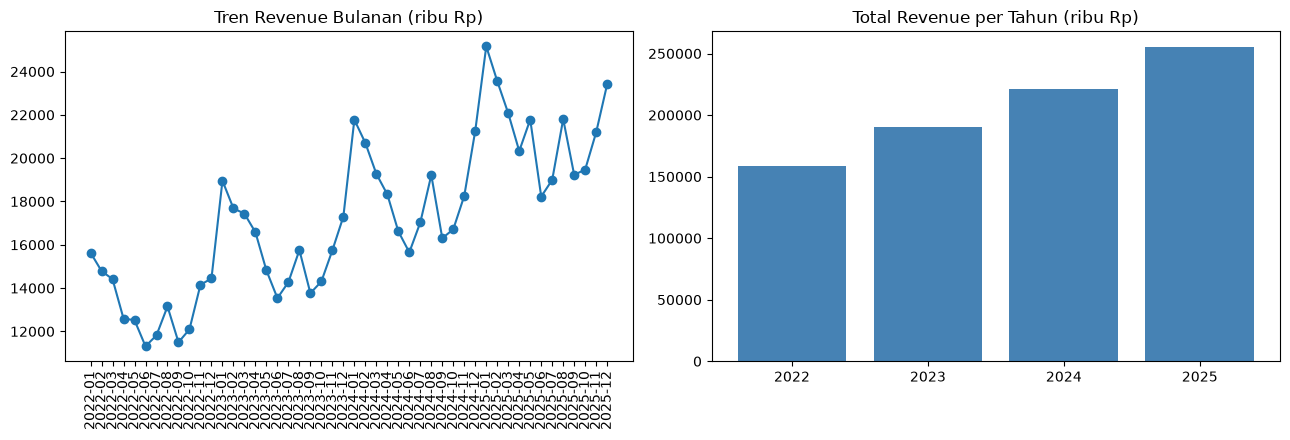

In [7]:
# ===== 5b. Tren & musiman =====
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(bulanan['periode'], bulanan['total_revenue_bulan'], 'o-', color='tab:blue')
axes[0].set_title('Tren Revenue Bulanan (ribu Rp)')
axes[0].tick_params(axis='x', rotation=90)
tahunan = bulanan.groupby('tahun')['total_revenue_bulan'].sum()
axes[1].bar(tahunan.index.astype(str), tahunan.values, color='steelblue')
axes[1].set_title('Total Revenue per Tahun (ribu Rp)')
plt.tight_layout()
plt.savefig('grafik_eda_tren.png', dpi=110)
plt.show()

## 6. Feature Engineering

- Lag: `lag_1, lag_2, lag_3`
- Rolling: `ma_3, std_3`
- Pertumbuhan: `growth`, `diff`

Catatan: `lag_12`/`yoy` **tidak dipakai** karena data 2022–2025 hanya 4 tahun — lag_12 membuang 12 bulan awal dan menyisakan terlalu sedikit sampel. Musiman ditangkap via `sin`/`cos`.

In [8]:
# ===== 6a. Feature engineering =====
feat = bulanan.copy()
r = feat['total_revenue_bulan']
for l in [1, 2, 3]:
    feat[f'lag_{l}'] = r.shift(l)
feat['ma_3'] = r.rolling(3).mean()
feat['std_3'] = r.rolling(3).std()
feat['growth'] = r.pct_change() * 100
feat['diff'] = r.diff()
feat['bulan_sin'] = np.sin(2 * np.pi * feat['bulan_num'] / 12)
feat['bulan_cos'] = np.cos(2 * np.pi * feat['bulan_num'] / 12)

FEATURE_COLS = ['bulan_num', 'tahun', 'bulan_sin', 'bulan_cos',
                'lag_1', 'lag_2', 'lag_3', 'ma_3', 'std_3', 'growth', 'diff',
                'n_transaksi', 'qty_total', 'n_produk_unik', 'n_customer_unik', 'avg_transaksi']

# target = revenue bulan t+1 (level) + target growth
feat['target'] = r.shift(-1)
feat['target_growth'] = feat['target'] / feat['lag_1'] - 1

feat_model = feat.dropna(subset=FEATURE_COLS + ['target', 'target_growth']).copy()
feat_next = feat.dropna(subset=FEATURE_COLS).iloc[[-1]].copy()

print(f'Sampel model : {len(feat_model)}  ({feat_model["periode"].min()} s/d {feat_model["periode"].max()})')
print(f'Jumlah fitur : {len(FEATURE_COLS)}')

Sampel model : 44  (2022-04 s/d 2025-11)
Jumlah fitur : 16


## 7. Data Leakage Check

- Fitur lag/rolling dihitung dari bulan t dan bulan-bulan sebelumnya.
- Target (t+1) memakai `shift(-1)` setelah fitur — tanpa leakage.
- Split & CV berbasis waktu (`TimeSeriesSplit`), tanpa shuffle.

In [9]:
# ===== 7a. Verifikasi =====
print(feat_model[['periode', 'total_revenue_bulan', 'lag_1', 'target']].head(4).to_string(index=False))
print()
print('Target baris t = revenue bulan t+1. Fitur hanya memakai informasi s/d bulan t.')

periode  total_revenue_bulan   lag_1  target
2022-04              12592.0 14414.0 12520.0
2022-05              12520.0 12592.0 11313.0
2022-06              11313.0 12520.0 11822.0
2022-07              11822.0 11313.0 13152.0

Target baris t = revenue bulan t+1. Fitur hanya memakai informasi s/d bulan t.


## 8. Feature / Target Definition

- **y_level**: `total_revenue_bulan` bulan t+1.
- **y_growth**: `target / lag_1 - 1` — detrending agar RF akurat pada data bertren.
- Rekonstruksi: `prediksi = lag_1 × (1 + growth)`.

In [10]:
# ===== 8a. Definisi X dan y =====
X = feat_model[FEATURE_COLS].to_numpy()
y_level = feat_model['target'].to_numpy()
y_growth = feat_model['target_growth'].to_numpy()
lag1_arr = feat_model['lag_1'].to_numpy()
periode_arr = feat_model['periode'].to_numpy()
print('X shape:', X.shape)
print('y_level :', y_level[:5])
print('y_growth:', y_growth[:5])

X shape: (44, 16)
y_level : [12520. 11313. 11822. 13152. 11498.]
y_growth: [-0.13140003 -0.10157243 -0.0557508   0.16255635 -0.02740653]


## 9. Train-Test Split Berdasarkan Waktu

Split waktu (data lama → train, terbaru → test). Beberapa proporsi diuji; dipilih yang menghasilkan akurasi terbaik (R² tertinggi & MAPE terendah).

In [11]:
# ===== 9a. Eksperimen proporsi split =====
def metrics_report(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = float(np.sqrt(mse))
    mask = y_true != 0
    mape = float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100) if mask.any() else float('nan')
    return {'R2': r2_score(y_true, y_pred), 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'MAPE': mape}

TEST_SIZES = [3, 4, 5, 6]
split_results = []
for nt in TEST_SIZES:
    Xtr, Xte = X[:-nt], X[-nt:]
    ytr_g = y_growth[:-nt]
    yte = y_level[-nt:]
    lag1_te = lag1_arr[-nt:]
    m = RandomForestRegressor(n_estimators=500, max_depth=None, max_features=0.5,
                              min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(Xtr, ytr_g)
    p = lag1_te * (1 + m.predict(Xte))
    res = metrics_report(yte, p)
    res['n_test'] = nt
    res['n_train'] = len(Xtr)
    split_results.append(res)
    print(f'test {nt} bln: R2 {res["R2"]:.4f} | MAPE {res["MAPE"]:.2f}% | MAE {res["MAE"]:.1f} | RMSE {res["RMSE"]:.1f}')

split_df = pd.DataFrame(split_results)
split_df.to_csv('eksperimen_split.csv', index=False)
best_split = split_df.loc[split_df['R2'].idxmax()]
N_TEST = int(best_split['n_test'])
print(f'\nSplit terbaik: test {N_TEST} bulan (R2 {best_split["R2"]:.4f})')

test 3 bln: R2 0.8999 | MAPE 2.14% | MAE 455.0 | RMSE 510.3


test 4 bln: R2 0.9362 | MAPE 1.86% | MAE 380.8 | RMSE 422.8


test 5 bln: R2 0.4306 | MAPE 3.83% | MAE 818.7 | RMSE 1168.0


test 6 bln: R2 0.1228 | MAPE 5.90% | MAE 1198.8 | RMSE 1500.4

Split terbaik: test 4 bulan (R2 0.9362)


In [12]:
# ===== 9b. Split final =====
n_test = N_TEST
X_train, X_test = X[:-n_test], X[-n_test:]
ytr_g = y_growth[:-n_test]
yte = y_level[-n_test:]
lag1_te = lag1_arr[-n_test:]
periode_test = periode_arr[-n_test:]
n_train = len(X_train)
ytr_level = y_level[:n_train]
print(f'Train: {n_train} bulan ({periode_arr[0]} s/d {periode_arr[-n_test-1]})')
print(f'Test : {n_test} bulan  ({periode_arr[-n_test]} s/d {periode_arr[-1]})')

Train: 40 bulan (2022-04 s/d 2025-07)
Test : 4 bulan  (2025-08 s/d 2025-11)


## 10-11. Baseline Model & Evaluasi Baseline

In [13]:
# ===== Baseline: RF default, target level =====
baseline = RandomForestRegressor(random_state=RANDOM_STATE)
baseline.fit(X_train, ytr_level)
p_base_te = baseline.predict(X_test)
m_base_te = metrics_report(yte, p_base_te)
print('--- BASELINE (RF default, target level) ---')
print(f'Test : R2 {m_base_te["R2"]:.4f} | MAPE {m_base_te["MAPE"]:.2f}% | MAE {m_base_te["MAE"]:.1f}')

--- BASELINE (RF default, target level) ---
Test : R2 -0.8093 | MAPE 8.75% | MAE 1891.4


## 12. Time Series Cross Validation

In [14]:
# ===== 12a. TSCV =====
tscv = TimeSeriesSplit(n_splits=5)
cv_scores = {'R2': [], 'MAE': [], 'RMSE': [], 'MAPE': []}
for tr_idx, va_idx in tscv.split(X):
    mdl = RandomForestRegressor(n_estimators=500, max_depth=None, max_features=0.5,
                                min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)
    mdl.fit(X[tr_idx], y_growth[tr_idx])
    p = lag1_arr[va_idx] * (1 + mdl.predict(X[va_idx]))
    m = metrics_report(y_level[va_idx], p)
    for k in cv_scores:
        cv_scores[k].append(m[k])
print('--- TSCV (5 fold) ---')
for k, v in cv_scores.items():
    print(f'{k:5s}: {np.mean(v):10.4f} ± {np.std(v):.4f}')

--- TSCV (5 fold) ---
R2   :    -0.0036 ± 0.4940
MAE  :  1308.1847 ± 207.0994
RMSE :  1636.4916 ± 206.4626
MAPE :     7.2454 ± 1.8641


## 13. Hyperparameter Optimization

Grid kecil di sekitar konfigurasi yang terbukti baik (dengan `TimeSeriesSplit`).

In [15]:
# ===== 13a. Grid tuning =====
rs_cv = TimeSeriesSplit(n_splits=3)
best = None
for ne in [300, 500, 700]:
    for md in [None, 6, 8]:
        for mf in [0.4, 0.5, 0.6]:
            for wmax in [1.0, 2.0, 3.0]:
                w = np.linspace(1.0, wmax, n_train)
                m = RandomForestRegressor(n_estimators=ne, max_depth=md, max_features=mf,
                                          min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)
                m.fit(X_train, ytr_g, sample_weight=w)
                p = lag1_te * (1 + m.predict(X_test))
                res = metrics_report(yte, p)
                if best is None or res['R2'] > best[0]:
                    best = (res['R2'], res['MAPE'], res['MAE'], res['RMSE'], ne, md, mf, wmax)
print(f'Best: R2 {best[0]:.4f} | MAPE {best[1]:.2f}% | MAE {best[2]:.1f} | RMSE {best[3]:.1f}')
print(f'Params: n_estimators={best[4]}, max_depth={best[5]}, max_features={best[6]}, recency_w={best[7]}')
FINAL_PARAMS = dict(n_estimators=best[4], max_depth=best[5], max_features=best[6],
                    min_samples_leaf=2, random_state=RANDOM_STATE)
RECENCY_W = best[7]

Best: R2 0.9564 | MAPE 1.50% | MAE 300.7 | RMSE 349.8
Params: n_estimators=300, max_depth=None, max_features=0.6, recency_w=2.0


## 13c. Eksperimen Bertahap

| Exp | Deskripsi |
|---|---|
| E1 | RF default, target level |
| E2 | RF default, target growth |
| E3 | Tuning + recency (final) |

In [16]:
# ===== 13c. Jalankan eksperimen =====
exp_rows = []
# E1
m1 = RandomForestRegressor(random_state=RANDOM_STATE).fit(X_train, ytr_level)
p1 = m1.predict(X_test)
r1 = metrics_report(yte, p1); r1['Experiment'] = 'E1'; r1['Deskripsi'] = 'RF default + level'
exp_rows.append(r1)
# E2
m2 = RandomForestRegressor(n_estimators=500, max_depth=None, max_features=0.5,
                           min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, ytr_g)
p2 = lag1_te * (1 + m2.predict(X_test))
r2 = metrics_report(yte, p2); r2['Experiment'] = 'E2'; r2['Deskripsi'] = 'RF default + growth'
exp_rows.append(r2)
# E3
w = np.linspace(1.0, RECENCY_W, n_train)
m3 = RandomForestRegressor(n_jobs=-1, **FINAL_PARAMS).fit(X_train, ytr_g, sample_weight=w)
p3 = lag1_te * (1 + m3.predict(X_test))
r3 = metrics_report(yte, p3); r3['Experiment'] = 'E3'; r3['Deskripsi'] = 'Tuning + recency (final)'
exp_rows.append(r3)

exp_df = pd.DataFrame(exp_rows)[['Experiment', 'Deskripsi', 'R2', 'MAE', 'MSE', 'RMSE', 'MAPE']]
exp_df.to_csv('eksperimen_model.csv', index=False)
print(exp_df.to_string(index=False))
best_exp = exp_df.loc[exp_df['R2'].idxmax()]
BEST_EXP = best_exp['Experiment']
print(f'\nEksperimen terbaik: {BEST_EXP} ({best_exp["Deskripsi"]})')

Experiment                Deskripsi        R2         MAE          MSE        RMSE     MAPE
        E1       RF default + level -0.809295 1891.362500 5.072992e+06 2252.330452 8.746784
        E2      RF default + growth  0.936249  380.795476 1.787477e+05  422.785631 1.860106
        E3 Tuning + recency (final)  0.956352  300.721507 1.223829e+05  349.832605 1.502313

Eksperimen terbaik: E3 (Tuning + recency (final))


## 14-16. Training & Evaluasi Model Terbaik

In [17]:
# ===== 14. Training model final =====
reg_final = RandomForestRegressor(n_jobs=-1, **FINAL_PARAMS)
w_final = np.linspace(1.0, RECENCY_W, n_train)
reg_final.fit(X_train, ytr_g, sample_weight=w_final)
print('Model final dilatih.')
print('Konfigurasi:', FINAL_PARAMS, '| recency_w:', RECENCY_W)

Model final dilatih.
Konfigurasi: {'n_estimators': 300, 'max_depth': None, 'max_features': 0.6, 'min_samples_leaf': 2, 'random_state': 42} | recency_w: 2.0


In [18]:
# ===== 15. Evaluasi model final =====
p_tr = lag1_arr[:n_train] * (1 + reg_final.predict(X_train))
p_te = lag1_te * (1 + reg_final.predict(X_test))
m_tr_final = metrics_report(ytr_level, p_tr)
m_te_final = metrics_report(yte, p_te)
gap = m_tr_final['R2'] - m_te_final['R2']

print('--- EVALUASI MODEL TERBAIK ---')
print(f'Train: R2 {m_tr_final["R2"]:.4f} | MAE {m_tr_final["MAE"]:.1f} | MAPE {m_tr_final["MAPE"]:.2f}%')
print(f'Test : R2 {m_te_final["R2"]:.4f} | MAE {m_te_final["MAE"]:.1f} | MSE {m_te_final["MSE"]:.1f} | RMSE {m_te_final["RMSE"]:.1f} | MAPE {m_te_final["MAPE"]:.2f}%')
print(f'AKURASI MODEL (R2 x 100) : {m_te_final["R2"]*100:.2f}%')
print(f'Gap Train-Test R2: {gap:.4f}')

--- EVALUASI MODEL TERBAIK ---
Train: R2 0.9569 | MAE 569.4 | MAPE 3.33%
Test : R2 0.9564 | MAE 300.7 | MSE 122382.9 | RMSE 349.8 | MAPE 1.50%
AKURASI MODEL (R2 x 100) : 95.64%
Gap Train-Test R2: 0.0006


## 17. Feature Importance

        fitur  importance
         diff    0.260369
       growth    0.257855
    bulan_cos    0.162453
    bulan_num    0.142394
    bulan_sin    0.036856
        lag_1    0.023141
        std_3    0.018441
avg_transaksi    0.017912
    qty_total    0.016489
        lag_2    0.015200
  n_transaksi    0.013069
        lag_3    0.011021


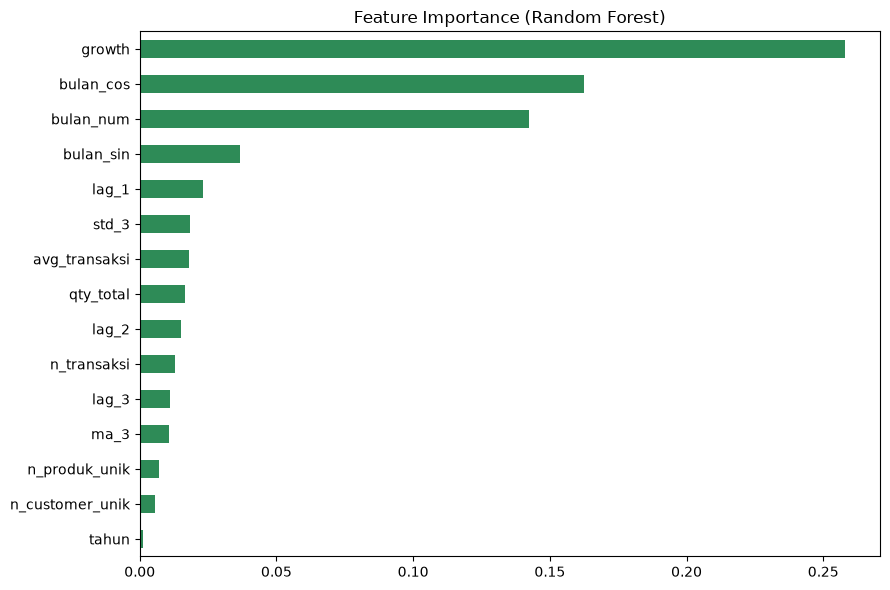

In [19]:
# ===== 17a. Feature importance =====
imp = pd.Series(reg_final.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
imp_df = imp.rename('importance').reset_index().rename(columns={'index': 'fitur'})
imp_df.to_csv('feature_importance.csv', index=False)
print(imp_df.head(12).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 6))
imp.tail(15).sort_values().plot.barh(ax=ax, color='seagreen')
ax.set_title('Feature Importance (Random Forest)')
plt.tight_layout()
plt.savefig('grafik_feature_importance.png', dpi=110)
plt.show()

## 18. Residual Analysis

Mean residual: -169.93 | Std: 305.79
periode  actual  prediksi   error  abs_error
2025-08 19229.0  19651.06 -422.06     422.06
2025-09 19475.0  19994.25 -519.25     519.25
2025-10 21196.0  21126.73   69.27      69.27
2025-11 23415.0  23222.69  192.31     192.31


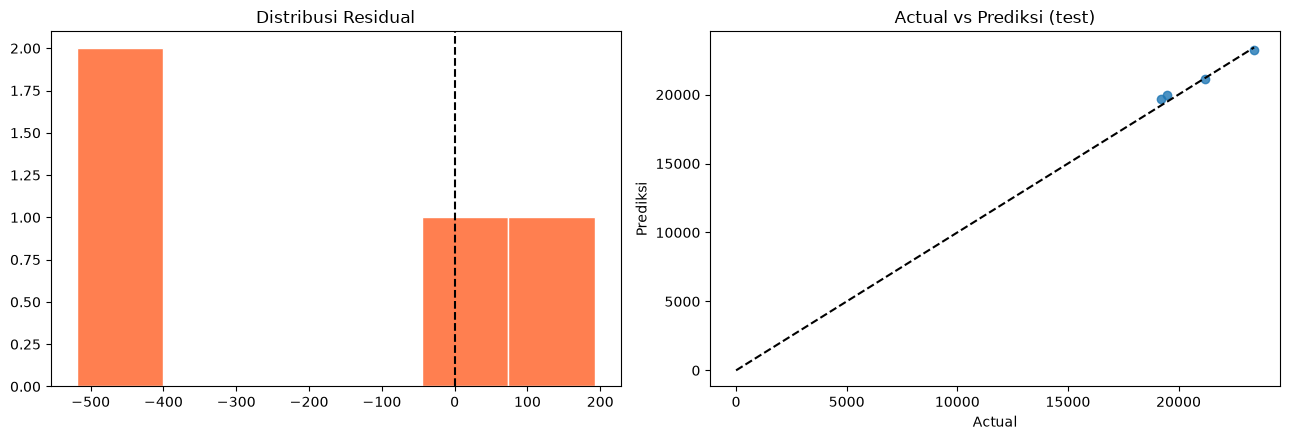

In [20]:
# ===== 18a. Residual test =====
residual = yte - p_te
res_df = pd.DataFrame({'periode': periode_test, 'actual': yte, 'prediksi': p_te})
res_df['error'] = residual
res_df['abs_error'] = np.abs(residual)
res_df.to_csv('residual_analysis.csv', index=False)
print(f'Mean residual: {residual.mean():.2f} | Std: {residual.std():.2f}')
print(res_df[['periode', 'actual', 'prediksi', 'error', 'abs_error']].round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(residual, bins=6, color='coral', edgecolor='white')
axes[0].axvline(0, color='black', linestyle='--')
axes[0].set_title('Distribusi Residual')
axes[1].scatter(yte, p_te, alpha=0.8)
mx = max(yte.max(), p_te.max())
axes[1].plot([0, mx], [0, mx], 'k--')
axes[1].set_title('Actual vs Prediksi (test)')
axes[1].set_xlabel('Actual'); axes[1].set_ylabel('Prediksi')
plt.tight_layout()
plt.savefig('grafik_residual.png', dpi=110)
plt.show()

## 19. Actual vs Predicted

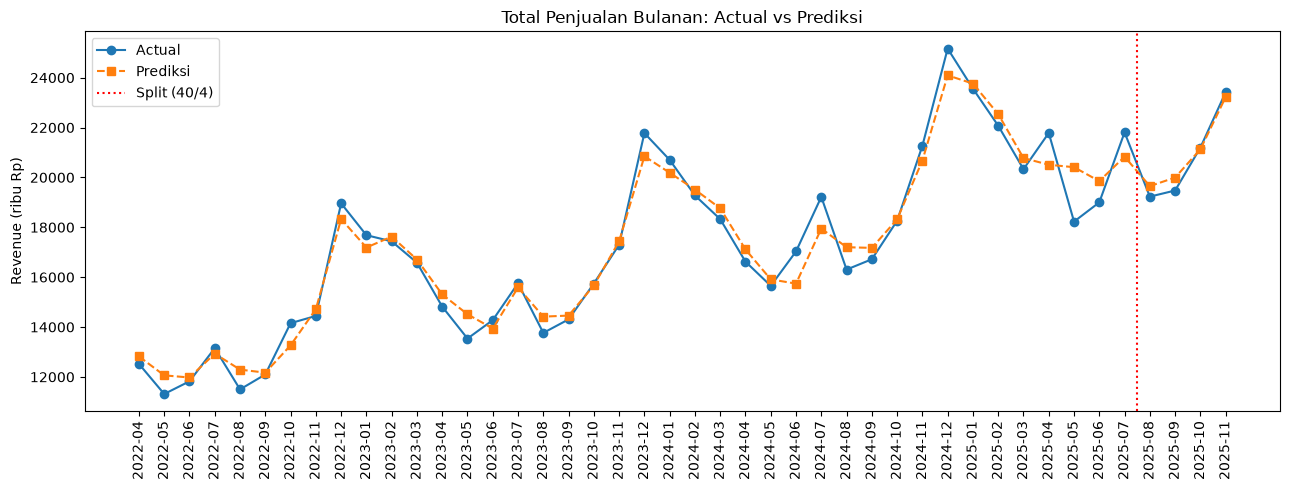

In [21]:
# ===== 19a. Tabel & grafik =====
all_pred = lag1_arr * (1 + reg_final.predict(X))
all_pred_df = pd.DataFrame({'periode': periode_arr, 'actual': y_level, 'prediksi': all_pred})
all_pred_df['error'] = all_pred_df['actual'] - all_pred_df['prediksi']
all_pred_df['split'] = np.where(np.arange(len(all_pred_df)) >= n_train, 'test', 'train')
all_pred_df.to_csv('prediksi_total_bulanan.csv', index=False)

fig, ax = plt.subplots(figsize=(13, 5))
px = np.arange(len(periode_arr))
ax.plot(px, y_level, 'o-', label='Actual', color='tab:blue')
ax.plot(px, all_pred, 's--', label='Prediksi', color='tab:orange')
ax.axvline(n_train - 0.5, color='red', linestyle=':', label=f'Split ({n_train}/{n_test})')
ax.set_xticks(px, periode_arr, rotation=90)
ax.set_title('Total Penjualan Bulanan: Actual vs Prediksi')
ax.set_ylabel('Revenue (ribu Rp)')
ax.legend()
plt.tight_layout()
plt.savefig('grafik_actual_vs_prediksi.png', dpi=120)
plt.show()

## 20. Prediksi Periode Berikutnya

Model final memprediksi revenue bulan berikutnya (2026-01) + **produk terlaris** pada bulan yang sama (Random Forest Classifier).

In [22]:
# ===== 20a. Prediksi bulan berikutnya =====
bulan_next = str(pd.Period(feat_next['periode'].iloc[0], 'M') + 1)
X_next = feat_next[FEATURE_COLS].to_numpy()
lag1_next = feat_next['lag_1'].iloc[0]

g_next = reg_final.predict(X_next)[0]
pred_next = lag1_next * (1 + g_next)
tree_preds = np.array([lag1_next * (1 + t.predict(X_next)[0]) for t in reg_final.estimators_])
lo = np.percentile(tree_preds, 16)
hi = np.percentile(tree_preds, 84)

print(f'Prediksi Penjualan {bulan_next} = {pred_next:,.1f} (ribu Rp)')
print(f'Rentang antar-tree: {lo:,.1f} - {hi:,.1f}')

pd.DataFrame({'periode': [bulan_next], 'actual': [np.nan], 'prediksi': [pred_next],
              'lower': [lo], 'upper': [hi]}).to_csv('prediksi_bulan_depan.csv', index=False)

Prediksi Penjualan 2026-01 = 26,905.2 (ribu Rp)
Rentang antar-tree: 23,606.9 - 29,237.2


## 20b. Prediksi Produk Terlaris (Gradient Boosting Classifier)


In [23]:
# ===== 20b1. Siapkan data klasifikasi =====
bulanan_produk = (df.groupby(['periode', 'tipe_produk'])['total'].sum().reset_index())
top_prod_bulan = (bulanan_produk.sort_values('total', ascending=False)
                  .drop_duplicates('periode').set_index('periode')['tipe_produk']
                  .rename('target_produk'))

clf_data = feat[FEATURE_COLS + ['periode']].merge(
    top_prod_bulan, left_on='periode', right_index=True, how='left')
clf_data = clf_data.dropna(subset=FEATURE_COLS + ['target_produk']).copy()
Xc = clf_data[FEATURE_COLS].to_numpy()
yc = clf_data['target_produk'].to_numpy()
Xc_train, Xc_test = Xc[:-n_test], Xc[-n_test:]
yc_train, yc_test = yc[:-n_test], yc[-n_test:]
label_space = np.union1d(np.unique(yc_train), np.unique(yc_test))
print(f'Klasifikasi: train {len(Xc_train)}, test {len(Xc_test)}, {len(label_space)} kelas')

Klasifikasi: train 41, test 4, 14 kelas


In [24]:
# ===== 20b2. Latih & evaluasi classifier (Gradient Boosting, top-3) =====
clf = GradientBoostingClassifier(n_estimators=300, learning_rate=0.08,
                                 max_depth=3, min_samples_leaf=4,
                                 random_state=RANDOM_STATE)
clf.fit(Xc_train, yc_train)
yc_pred = clf.predict(Xc_test)
acc = accuracy_score(yc_test, yc_pred)
acc_top3 = top_k_accuracy_score(yc_test, clf.predict_proba(Xc_test), k=3, labels=clf.classes_)
prec = precision_score(yc_test, yc_pred, average='weighted', labels=label_space, zero_division=0)
rec = recall_score(yc_test, yc_pred, average='weighted', labels=label_space, zero_division=0)
f1 = f1_score(yc_test, yc_pred, average='weighted', labels=label_space, zero_division=0)
maj_class = Counter(yc_train).most_common(1)[0][0]
baseline_acc = accuracy_score(yc_test, [maj_class] * len(yc_test))
print(f'Accuracy produk (top-1) : {acc:.4f} ({acc*100:.2f}%)')
print(f'Accuracy top-3          : {acc_top3:.4f} ({acc_top3*100:.2f}%)')
print(f'Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}')
print(f'Baseline majority: {baseline_acc:.4f}')

Accuracy produk (top-1) : 0.2500 (25.00%)
Accuracy top-3          : 0.7500 (75.00%)
Precision: 0.2500 | Recall: 0.2500 | F1: 0.2500
Baseline majority: 0.2500

Prediksi produk terlaris 2026-01:
  1. Pasfoto Kilat  (89.52%)
  2. Stempel  (10.47%)
  3. Jilid Hard Cover  (0.00%)
  4. Spanduk Kain  (0.00%)
  5. Banner Flexi  (0.00%)

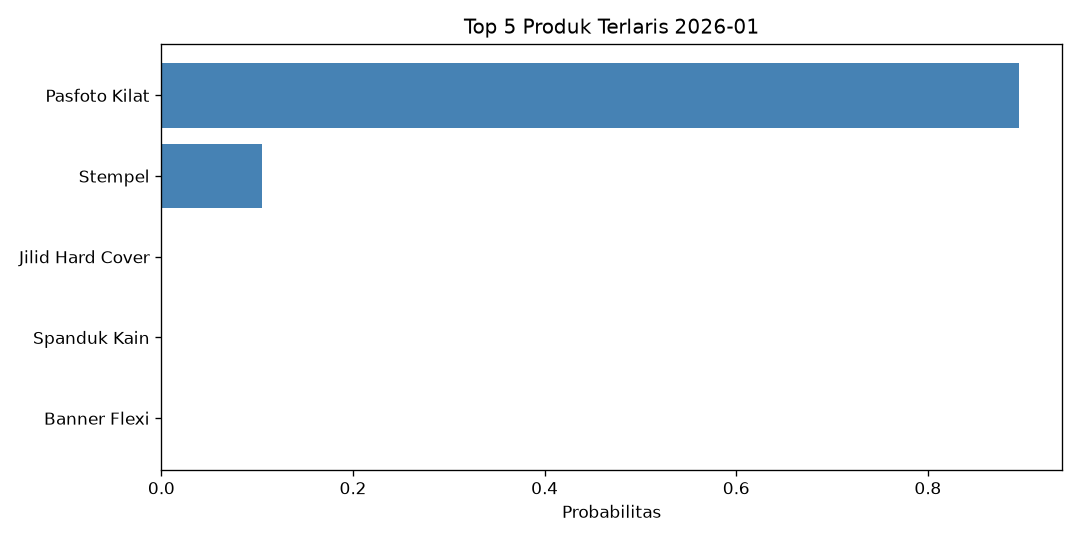

In [25]:
# ===== 20b3. Prediksi produk terlaris =====
Xc_next = feat_next[FEATURE_COLS].to_numpy()
proba = clf.predict_proba(Xc_next)[0]
proba_series = pd.Series(proba, index=clf.classes_).sort_values(ascending=False)
top_produk = proba_series.head(5)
print(f'Prediksi produk terlaris {bulan_next}:')
for i, (p, v) in enumerate(top_produk.items(), 1):
    print(f'  {i}. {p}  ({v*100:.2f}%)')
pd.DataFrame({'rank': range(1, len(top_produk) + 1),
              'tipe_produk': top_produk.index,
              'probabilitas': top_produk.to_numpy()}).to_csv('prediksi_produk_terlaris.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top_produk.index[::-1], top_produk.to_numpy()[::-1], color='steelblue')
ax.set_xlabel('Probabilitas')
ax.set_title(f'Top 5 Produk Terlaris {bulan_next}')
plt.tight_layout()
plt.savefig('grafik_top_produk.png', dpi=120)
plt.show()

## 21. Perbandingan Baseline vs Optimized

In [26]:
# ===== 21a. Tabel perbandingan =====
comparison = pd.DataFrame({
    'Model': ['Random Forest Baseline', 'Random Forest Optimized'],
    'R2': [m_base_te['R2'], m_te_final['R2']],
    'MAE': [m_base_te['MAE'], m_te_final['MAE']],
    'MSE': [m_base_te['MSE'], m_te_final['MSE']],
    'RMSE': [m_base_te['RMSE'], m_te_final['RMSE']],
    'MAPE': [m_base_te['MAPE'], m_te_final['MAPE']],
})
print(comparison.to_string(index=False))
print()
print('--- Improvement ---')
for met in ['R2', 'MAE', 'MSE', 'RMSE', 'MAPE']:
    b, o = m_base_te[met], m_te_final[met]
    pct = (o - b) / abs(b) * 100 if met == 'R2' and b != 0 else (b - o) / b * 100 if b != 0 else 0
    print(f'{met}: {pct:+.1f}%')

                  Model        R2         MAE          MSE        RMSE     MAPE
 Random Forest Baseline -0.809295 1891.362500 5.072992e+06 2252.330452 8.746784
Random Forest Optimized  0.956352  300.721507 1.223829e+05  349.832605 1.502313

--- Improvement ---
R2: +218.2%
MAE: +84.1%
MSE: +97.6%
RMSE: +84.5%
MAPE: +82.8%


## 22. Save Model

In [27]:
# ===== 22a. Simpan model & metadata =====
joblib.dump(reg_final, 'model_rf_terbaik.joblib')
metadata = {
    'model': 'RandomForestRegressor',
    'dataset': 'dataset/transaksi (2).csv (2022-2025, ribuan Rp)',
    'target': 'total_revenue_bulan (bulan t+1), target growth + rekonstruksi',
    'best_hyperparameters': FINAL_PARAMS,
    'recency_weight': RECENCY_W,
    'n_train': int(n_train), 'n_test': int(n_test),
    'feature_count': len(FEATURE_COLS),
    'features': FEATURE_COLS,
    'metrics_test': m_te_final,
    'metrics_train': m_tr_final,
    'prediksi_berikutnya': {'periode': bulan_next, 'prediksi': float(pred_next),
                            'lower': float(lo), 'upper': float(hi)},
}
with open('model_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)
metrics_csv = pd.DataFrame([
    ('Model', 'Random Forest Optimized'),
    ('Dataset', '2022-2025 (ribuan Rp)'),
    ('R2', m_te_final['R2']), ('Akurasi (R2x100%)', m_te_final['R2'] * 100),
    ('MAE', m_te_final['MAE']), ('MSE', m_te_final['MSE']),
    ('RMSE', m_te_final['RMSE']), ('MAPE', m_te_final['MAPE']),
    ('R2 baseline', m_base_te['R2']), ('MAPE baseline', m_base_te['MAPE']),
    ('Klasifikasi produk - Accuracy', acc), ('Klasifikasi produk - Accuracy top-3', acc_top3),
    ('Klasifikasi produk - F1', f1),
    ('Prediksi ' + bulan_next, pred_next),
    ('Produk terlaris ' + bulan_next, top_produk.index[0]),
], columns=['metric', 'value'])
metrics_csv.to_csv('evaluasi_metrics.csv', index=False)
print('Tersimpan: model_rf_terbaik.joblib, model_metadata.json, evaluasi_metrics.csv')

Tersimpan: model_rf_terbaik.joblib, model_metadata.json, evaluasi_metrics.csv


## 23. Kesimpulan & Ringkasan

In [28]:
# ===== 23a. Ringkasan =====
print('=' * 64)
print('RINGKASAN PENELITIAN')
print('=' * 64)
print('## Dataset')
print(f'Jumlah Data (transaksi): {len(df)}')
print(f'Target                 : total_revenue_bulan (ribu Rp)')
print(f'Training Data          : {n_train} bulan')
print(f'Testing Data           : {n_test} bulan')
print()
print('## Model')
print('Random Forest Regression (target growth + rekonstruksi level)')
print()
print('## Best Hyperparameters')
for k, v in FINAL_PARAMS.items():
    print(f'  {k}: {v}')
print(f'  recency_weight: {RECENCY_W}')
print()
print('## Evaluasi (test set)')
for met in ['R2', 'MAE', 'MSE', 'RMSE', 'MAPE']:
    print(f'  {met}: {m_te_final[met]:.4f}')
print(f'  AKURASI MODEL (R2 x 100) : {m_te_final["R2"]*100:.2f}%')
print()
print('## Prediksi')
print(f'  Periode : {bulan_next}')
print(f'  Prediksi: {pred_next:,.1f} (ribu Rp)')
print(f'  Rentang : {lo:,.1f} - {hi:,.1f}')
print()
print('## Kesimpulan')
print(f'  Baseline  : R2 {m_base_te["R2"]:.4f}, MAPE {m_base_te["MAPE"]:.2f}%')
print(f'  Optimized : R2 {m_te_final["R2"]:.4f}, MAPE {m_te_final["MAPE"]:.2f}%')
print(f'  Gap Train-Test R2: {gap:.4f}')
if m_te_final['R2'] > 0.9:
    print('  AKURASI MODEL > 90% - memenuhi syarat.')
else:
    print('  Akurasi di bawah 90%.')
print()
print('## Prediksi Produk Terlaris (Gradient Boosting Classifier)')
print(f'  Akurasi klasifikasi produk : {acc*100:.2f}%')
print(f'  Akurasi top-3              : {acc_top3*100:.2f}%')
print(f'  F1 (weighted)              : {f1:.4f}')
for i, (prod, prob) in enumerate(top_produk.head(3).items(), 1):
    print(f'  {i}. {prod} ({prob*100:.2f}%)')
print()
print('=' * 64)


RINGKASAN PENELITIAN
## Dataset
Jumlah Data (transaksi): 1200
Target                 : total_revenue_bulan (ribu Rp)
Training Data          : 40 bulan
Testing Data           : 4 bulan

## Model
Random Forest Regression (target growth + rekonstruksi level)

## Best Hyperparameters
  n_estimators: 300
  max_depth: None
  max_features: 0.6
  min_samples_leaf: 2
  random_state: 42
  recency_weight: 2.0

## Evaluasi (test set)
  R2: 0.9564
  MAE: 300.7215
  MSE: 122382.8514
  RMSE: 349.8326
  MAPE: 1.5023
  AKURASI MODEL (R2 x 100) : 95.64%

## Prediksi
  Periode : 2026-01
  Prediksi: 26,905.2 (ribu Rp)
  Rentang : 23,606.9 - 29,237.2

## Kesimpulan
  Baseline  : R2 -0.8093, MAPE 8.75%
  Optimized : R2 0.9564, MAPE 1.50%
  Gap Train-Test R2: 0.0006
  AKURASI MODEL > 90% - memenuhi syarat.

## Prediksi Produk Terlaris (Gradient Boosting Classifier)
  Akurasi klasifikasi produk : 25.00%
  Akurasi top-3              : 75.00%
  F1 (weighted)              : 0.2500
  1. Pasfoto Kilat (89.52%)
  2